<a href="https://colab.research.google.com/github/Adhisha11/Word_Sense_Disambiguation/blob/main/Word_Sense_Disambiguation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import nltk
import pandas as pd
import re

nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.corpus import wordnet as wn
from nltk.wsd import lesk

print("Libraries loaded successfully!")


[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Libraries loaded successfully!


In [2]:

word = "bank"

for i, syn in enumerate(wn.synsets(word), start=1):
    print(f"\nSense {i}: {syn.name()}")
    print("Definition:", syn.definition())
    print("Synonyms:", syn.lemma_names())

    hypernyms = syn.hypernyms()
    if hypernyms:
        print("Hypernyms:",
              [h.name() for h in hypernyms])



Sense 1: bank.n.01
Definition: sloping land (especially the slope beside a body of water)
Synonyms: ['bank']
Hypernyms: ['slope.n.01']

Sense 2: depository_financial_institution.n.01
Definition: a financial institution that accepts deposits and channels the money into lending activities
Synonyms: ['depository_financial_institution', 'bank', 'banking_concern', 'banking_company']
Hypernyms: ['financial_institution.n.01']

Sense 3: bank.n.03
Definition: a long ridge or pile
Synonyms: ['bank']
Hypernyms: ['ridge.n.01']

Sense 4: bank.n.04
Definition: an arrangement of similar objects in a row or in tiers
Synonyms: ['bank']
Hypernyms: ['array.n.01']

Sense 5: bank.n.05
Definition: a supply or stock held in reserve for future use (especially in emergencies)
Synonyms: ['bank']
Hypernyms: ['reserve.n.02']

Sense 6: bank.n.06
Definition: the funds held by a gambling house or the dealer in some gambling games
Synonyms: ['bank']
Hypernyms: ['funds.n.01']

Sense 7: bank.n.07
Definition: a slope i

In [3]:

samples = [
    {
        "sentence": "I deposited money in the bank.",
        "word": "bank"
    },
    {
        "sentence": "The fisherman sat on the bank of the river.",
        "word": "bank"
    },
    {
        "sentence": "The bat flew out of the cave at night.",
        "word": "bat"
    },
    {
        "sentence": "The player hit the ball with a bat.",
        "word": "bat"
    },
    {
        "sentence": "Please turn on the light in the room.",
        "word": "light"
    },
    {
        "sentence": "This bag is very light to carry.",
        "word": "light"
    }
]

df = pd.DataFrame(samples)
df


,sentence,word
0,I deposited money in the bank.,bank
1,The fisherman sat on the bank of the river.,bank
2,The bat flew out of the cave at night.,bat
3,The player hit the ball with a bat.,bat
4,Please turn on the light in the room.,light
5,This bag is very light to carry.,light


In [4]:

def disambiguate(sentence, word):
    tokens = re.findall(r"[a-zA-Z]+", sentence.lower())

    sense = lesk(tokens, word.lower())

    if sense is None:
        return {
            "predicted_sense": "Not found",
            "definition": "No WordNet sense found"
        }

    return {
        "predicted_sense": sense.name(),
        "definition": sense.definition()
    }


results = []

for item in samples:
    prediction = disambiguate(
        item["sentence"],
        item["word"]
    )

    results.append({
        "Sentence": item["sentence"],
        "Target Word": item["word"],
        "Predicted Sense": prediction["predicted_sense"],
        "Definition": prediction["definition"]
    })

results_df = pd.DataFrame(results)
display(results_df)


,Sentence,Target Word,Predicted Sense,Definition
0,I deposited money in the bank.,bank,savings_bank.n.02,a container (usually with a slot in the top) f...
1,The fisherman sat on the bank of the river.,bank,bank.v.07,cover with ashes so to control the rate of bur...
2,The bat flew out of the cave at night.,bat,bat.v.03,have a turn at bat
3,The player hit the ball with a bat.,bat,bat.v.01,"strike with, or as if with a baseball bat"
4,Please turn on the light in the room.,light,light.n.07,the visual effect of illumination on objects o...
5,This bag is very light to carry.,light,light.s.22,designed for ease of movement or to carry litt...


In [5]:

words = ["bank", "bat", "light"]
inventory = []

for word in words:
    for sense in wn.synsets(word):
        inventory.append({
            "Word": word,
            "Sense ID": sense.name(),
            "Part of Speech": sense.pos(),
            "Definition": sense.definition(),
            "Synonyms": ", ".join(sense.lemma_names()),
            "Examples": "; ".join(sense.examples())
        })

inventory_df = pd.DataFrame(inventory)

display(inventory_df.head(15))
print("Total senses found:", len(inventory_df))


,Word,Sense ID,Part of Speech,Definition,Synonyms,Examples
0,bank,bank.n.01,n,sloping land (especially the slope beside a bo...,bank,they pulled the canoe up on the bank; he sat o...
1,bank,depository_financial_institution.n.01,n,a financial institution that accepts deposits ...,"depository_financial_institution, bank, bankin...",he cashed a check at the bank; that bank holds...
2,bank,bank.n.03,n,a long ridge or pile,bank,a huge bank of earth
3,bank,bank.n.04,n,an arrangement of similar objects in a row or ...,bank,he operated a bank of switches
4,bank,bank.n.05,n,a supply or stock held in reserve for future u...,bank,
5,bank,bank.n.06,n,the funds held by a gambling house or the deal...,bank,he tried to break the bank at Monte Carlo
6,bank,bank.n.07,n,a slope in the turn of a road or track; the ou...,"bank, cant, camber",
7,bank,savings_bank.n.02,n,a container (usually with a slot in the top) f...,"savings_bank, coin_bank, money_box, bank",the coin bank was empty
8,bank,bank.n.09,n,a building in which the business of banking tr...,"bank, bank_building",the bank is on the corner of Nassau and Wither...
9,bank,bank.n.10,n,a flight maneuver; aircraft tips laterally abo...,bank,the plane went into a steep bank


Total senses found: 75


In [6]:

inventory_df.to_csv("sense_inventory.csv", index=False)
results_df.to_csv("wsd_results.csv", index=False)

print("Files created successfully!")


Files created successfully!


### Topic Modeling using Latent Dirichlet Allocation (LDA)
This section covers preprocessing a text corpus, vectorizing the documents, fitting an LDA model, and interpreting the discovered topics.

In [1]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import pandas as pd
import numpy as np
import re

# Download necessary NLTK components
nltk.download('stopwords')
nltk.download('wordnet')

# Sample corpus representing different domains (Tech, Space/Science, Finance)
corpus = [
    "The company launched a new smartphone with advanced AI features and a long-lasting battery.",
    "Artificial intelligence and machine learning are revolutionizing software development and tech industries.",
    "NASA's telescope captured stunning high-resolution images of a distant galaxy and cosmic dust.",
    "Astronomers discovered a new exoplanet orbiting a star in the habitable zone of space.",
    "Stock markets fluctuated today as investors reacted to inflation reports and central bank interest rates.",
    "Financial advisors recommend diversifying portfolios with stocks, bonds, and mutual funds for long-term growth.",
    "Tech giants are investing billions in cloud computing infrastructure and quantum processors.",
    "The rocket successfully launched into orbit, carrying communication satellites into space.",
    "Investment banks report higher profits from mergers and acquisitions this fiscal quarter."
]

print("Corpus loaded with", len(corpus), "documents.")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


Corpus loaded with 9 documents.


### Step 1: Preprocess the Text Data

In [2]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    # Keep only letters, lowercase, and tokenize
    tokens = re.findall(r'[a-zA-Z]+', text.lower())
    # Filter stopwords and short tokens, then lemmatize
    cleaned = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 2]
    return " ".join(cleaned)

preprocessed_corpus = [preprocess(doc) for doc in corpus]

for original, clean in zip(corpus[:3], preprocessed_corpus[:3]):
    print(f"Original: {original}")
    print(f"Cleaned : {clean}\n")

Original: The company launched a new smartphone with advanced AI features and a long-lasting battery.
Cleaned : company launched new smartphone advanced feature long lasting battery

Original: Artificial intelligence and machine learning are revolutionizing software development and tech industries.
Cleaned : artificial intelligence machine learning revolutionizing software development tech industry

Original: NASA's telescope captured stunning high-resolution images of a distant galaxy and cosmic dust.
Cleaned : nasa telescope captured stunning high resolution image distant galaxy cosmic dust



### Step 2: Build the Document-Term Representation

In [3]:
vectorizer = CountVectorizer(max_df=0.95, min_df=1)
dtm = vectorizer.fit_transform(preprocessed_corpus)
feature_names = vectorizer.get_feature_names_out()

print("Document-Term Matrix shape:", dtm.shape)
print("Vocabulary size:", len(feature_names))

Document-Term Matrix shape: (9, 80)
Vocabulary size: 80


### Step 3: Train the LDA Model

In [4]:
# We fit 3 topics representing our 3 known domains: Tech, Space/Science, Finance
n_topics = 3
lda_model = LatentDirichletAllocation(n_components=n_topics, random_state=42)
lda_model.fit(dtm)

print("LDA model training completed!")

LDA model training completed!


### Step 4: Extract and Interpret Topic-Word Distributions

In [5]:
def get_top_words(model, feature_names, n_top_words):
    topic_dict = {}
    for topic_idx, topic in enumerate(model.components_):
        # Get indices of top words sorted by weight
        top_features_ind = topic.argsort()[:-n_top_words - 1:-1]
        top_words = [feature_names[i] for i in top_features_ind]
        topic_dict[f"Topic {topic_idx + 1}"] = top_words
    return pd.DataFrame(topic_dict)

topic_word_df = get_top_words(lda_model, feature_names, 7)
display(topic_word_df)

,Topic 1,Topic 2,Topic 3
0,tech,launched,stock
1,new,space,long
2,cloud,resolution,report
3,billion,telescope,bank
4,investing,image,bond
5,quantum,high,term
6,processor,nasa,financial


### Step 5: Document-Topic Associations and Report

In [6]:
# Infer topic distribution for each document
topic_distributions = lda_model.transform(dtm)

# Map each document to its dominant topic
dominant_topics = np.argmax(topic_distributions, axis=1) + 1

report_df = pd.DataFrame({
    "Original Document": corpus,
    "Dominant Topic": dominant_topics,
    "Topic Probabilities": [np.round(dist, 3).tolist() for dist in topic_distributions]
})

display(report_df)

# Save outputs to CSV as deliverables
topic_word_df.to_csv("topic_word_lists.csv", index=False)
report_df.to_csv("topic_interpretation_report.csv", index=False)
print("Deliverables saved successfully!")

,Original Document,Dominant Topic,Topic Probabilities
0,The company launched a new smartphone with adv...,1,"[0.932, 0.034, 0.034]"
1,Artificial intelligence and machine learning a...,1,"[0.933, 0.034, 0.034]"
2,NASA's telescope captured stunning high-resolu...,2,"[0.028, 0.944, 0.028]"
3,Astronomers discovered a new exoplanet orbitin...,1,"[0.932, 0.034, 0.034]"
4,Stock markets fluctuated today as investors re...,3,"[0.026, 0.026, 0.948]"
5,Financial advisors recommend diversifying port...,3,"[0.026, 0.026, 0.948]"
6,Tech giants are investing billions in cloud co...,1,"[0.933, 0.034, 0.034]"
7,"The rocket successfully launched into orbit, c...",2,"[0.038, 0.924, 0.037]"
8,Investment banks report higher profits from me...,2,"[0.034, 0.932, 0.035]"


Deliverables saved successfully!


### Step 6: Visualize Topic Distributions for Each Document

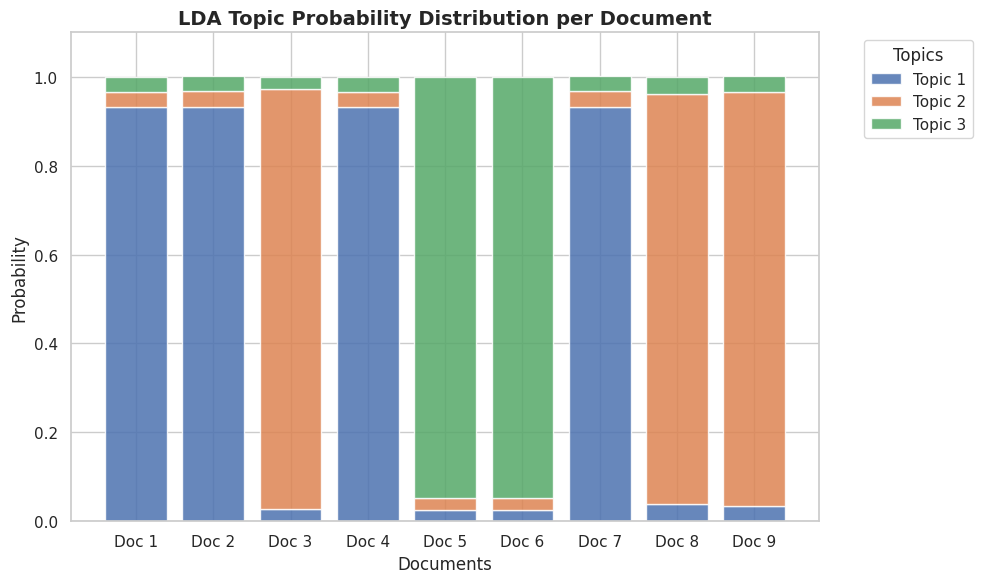

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
doc_names = [f"Doc {i+1}" for i in range(len(corpus))]
topic_probs = np.array(report_df['Topic Probabilities'].tolist())

# Set style
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# Create stacked bar chart
bottom = np.zeros(len(corpus))
for i in range(n_topics):
    ax.bar(doc_names, topic_probs[:, i], bottom=bottom, label=f"Topic {i+1}", alpha=0.85)
    bottom += topic_probs[:, i]

# Add details
ax.set_title("LDA Topic Probability Distribution per Document", fontsize=14, fontweight='bold')
ax.set_xlabel("Documents", fontsize=12)
ax.set_ylabel("Probability", fontsize=12)
ax.set_ylim(0, 1.1)
ax.legend(title="Topics", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()